# LJ 1-2 — Lernschritt 2: Musterlösung

**Nur für die Lehrkraft.** Dieses Notebook rechnet die Teilaufgaben aus
Lernschritt 2 ("Unsere Datengrundlage analysieren") anhand der echten
10kGNAD-Dateien vollständig durch, damit vorab klar ist, welche Ergebnisse bei
korrekter Bearbeitung zu erwarten sind. Es ersetzt nicht die Auftragskarte —
die Lernenden bekommen diesen Code nicht.

**Fassung:** an die aktuelle Auftragskarte (Lizenz zuerst, dann Datenanalyse
inkl. Split-Entdeckung) angepasst. Wichtig gegenüber einer älteren Fassung
dieses Notebooks: Die Klassenverteilung und die Textlängen werden jetzt aus
`train.csv` **allein** berechnet, nicht aus train+test zusammen — genau das
verlangt Aufgabe 2c. Die kombinierten Zahlen (z. B. Panorama 1.678) tauchen
hier nicht mehr als Erwartungswert auf.

Teilaufgaben laut Auftragskarte:

- **2a/2b** — Lizenztext prüfen und Einsatz bei Kerner & Partner beurteilen (reine Lese-/Urteilsarbeit, kein Code)
- **2c** — Klassenverteilung (train.csv)
- **2d** — Textlängen im Vergleich (train.csv)
- **2e** — Textbeispiele sichten, Ausreißer identifizieren
- **2f** — Kriterien für gute Trainingsdaten, Aufbereitungsbedarf
- **2g** — test.csv laden und mit train.csv vergleichen
- **2h** — Erörterung: warum zwei Dateien? (Diskussion, kein Code)
- **2i** — Split-Regel (Diskussion/Entscheidung, kein Code)
- **2j** — Fachliche Bezeichnung train.csv/test.csv (Diskussion, kein Code)
- **2k** — Bausteine für den Datensteckbrief

## 2a/2b — Lizenzprüfung (Erwartungshorizont)

10kGNAD steht unter **CC BY-NC-SA 4.0**: Namensnennung erforderlich (BY),
ausschließlich nicht-kommerzielle Nutzung erlaubt (NC), Weitergabe nur unter
derselben Lizenz (SA). Die Texte stammen aus dem *One Million Posts Corpus*
der Tageszeitung *Der Standard* — reale, urheberrechtlich geschützte
Presseartikel.

**2b, erwartetes Urteil: Nein.** Ein Einsatz eines daraus trainierten Modells
im *Kundengeschäft* von Kerner & Partner wäre eine kommerzielle Nutzung und
damit durch die NC-Klausel ausgeschlossen — unabhängig davon, ob die
Rohdaten selbst weitergegeben werden. Die aktuelle, schulische Nutzung zu
Übungszwecken ist davon unberührt und lizenzkonform; im Unterrichtsgespräch
sollte dieser Unterschied (Schule/Experiment vs. späterer Produktivbetrieb)
ausdrücklich benannt werden, da 2c unmittelbar mit „vorausgesetzt, wir dürfen
die Daten nutzen" fortsetzt.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Stolperfalle (bewusst nicht in der Auftragskarte vorweggenommen):
# Trennzeichen Semikolon, keine Kopfzeile, Text selbst enthaelt Semikola
# und mit einfachem Anfuehrungszeichen maskierte Stellen.
train = pd.read_csv("train.csv", sep=";", header=None, names=["label", "text"],
                     encoding="utf-8", quotechar="'")
test = pd.read_csv("test.csv", sep=";", header=None, names=["label", "text"],
                    encoding="utf-8", quotechar="'")

print(f"Zeilen train: {len(train)} | Zeilen test: {len(test)}")

Zeilen train: 9245 | Zeilen test: 1028


## 2c — Klassenverteilung (train.csv)

In [3]:
verteilung = train["label"].value_counts().sort_values(ascending=False)
verteilung

label
Panorama         1510
Web              1509
International    1360
Wirtschaft       1270
Sport            1081
Inland            913
Etat              601
Wissenschaft      516
Kultur            485
Name: count, dtype: int64

In [4]:
verteilung_prozent = (verteilung / verteilung.sum() * 100).round(1)
pd.DataFrame({"Anzahl": verteilung, "Anteil (%)": verteilung_prozent})

,Anzahl,Anteil (%)
label,,
Panorama,1510,16.3
Web,1509,16.3
International,1360,14.7
Wirtschaft,1270,13.7
Sport,1081,11.7
Inland,913,9.9
Etat,601,6.5
Wissenschaft,516,5.6
Kultur,485,5.2


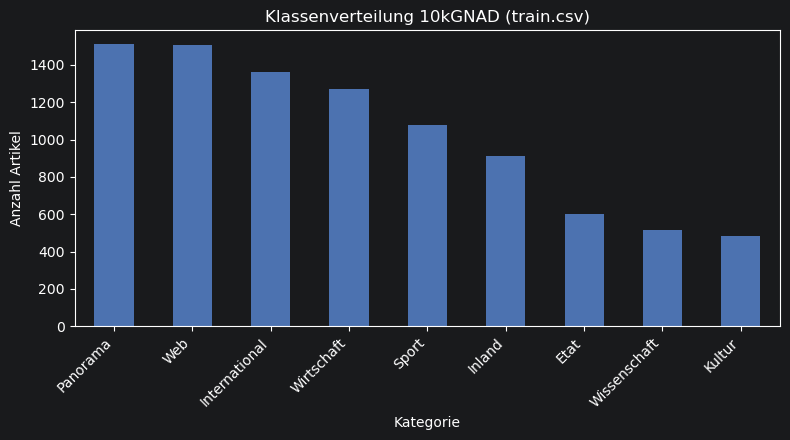

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
verteilung.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_ylabel("Anzahl Artikel")
ax.set_xlabel("Kategorie")
ax.set_title("Klassenverteilung 10kGNAD (train.csv)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("klassenverteilung.png", dpi=130)
plt.show()

**Erwartete Beobachtung:** Panorama (1.510) und Web (1.509) liegen praktisch
gleichauf an der Spitze — ein einziger Artikel Unterschied. Beide Antworten
sind als "Mehrheitsklasse" zu akzeptieren. Die kleinste Klasse ist Kultur
(485, 5,2 %); das Verhältnis größte zu kleinste Klasse liegt bei rund 3,1.
Das ist der Fund, der in Lernschritt 3 (Gütemaß) die Begründung tragen soll —
nicht vorher mitteilen.

## 2d — Textlängen im Vergleich (train.csv)

In [7]:
train["textlaenge"] = train["text"].str.len()

laenge_je_kategorie = train.groupby("label")["textlaenge"].agg(
    ["mean", "median", "min", "max"]
).round(0).sort_values("mean", ascending=False)
laenge_je_kategorie

,mean,median,min,max
label,,,,
Inland,3272.0,2835.0,47,19011
Kultur,3017.0,2441.0,52,15948
Wissenschaft,2998.0,2496.0,122,14040
Sport,2656.0,2369.0,25,15455
Panorama,2643.0,2257.0,79,18044
Wirtschaft,2603.0,2426.0,91,13714
Etat,2352.0,1748.0,90,17972
International,2334.0,1922.0,49,14123
Web,2101.0,1643.0,34,22120


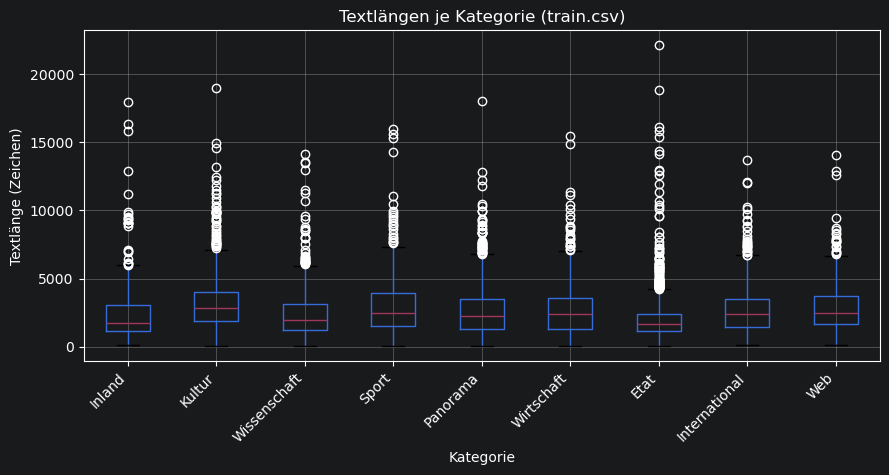

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
reihenfolge = laenge_je_kategorie.index
train.boxplot(column="textlaenge", by="label", ax=ax,
              positions=range(len(reihenfolge)))
ax.set_xticklabels(reihenfolge, rotation=45, ha="right")
ax.set_ylabel("Textlänge (Zeichen)")
ax.set_xlabel("Kategorie")
ax.set_title("Textlängen je Kategorie (train.csv)")
plt.suptitle("")
plt.tight_layout()
plt.savefig("textlaengen_boxplot.png", dpi=130)
plt.show()

**Erwartete Beobachtung:** Die mittleren Textlängen unterscheiden sich
zwischen den Kategorien spürbar (Inland am längsten, Web am kürzesten), aber
nicht dramatisch — kein Hinweis darauf, dass eine Kategorie allein an der
Textlänge erkennbar wäre. Auffällig ist vor allem die enorme Streuung
innerhalb jeder Kategorie (Ausreißer bis über 15.000 Zeichen) — ein Boxplot
ist hier einem reinen Mittelwert-Balkendiagramm klar überlegen, weil er diese
Streuung sichtbar macht. Wichtig für später (Vokabular-/Normalisierungsarbeit
in LJ 1-6): Textlänge ist kein triviales Verratsmerkmal.

## 2e — Textbeispiele sichten (Ausreißer)

In [9]:
train["woerter"] = train["text"].str.split().apply(len)
kuerzeste = train.sort_values("woerter").head(5)
kuerzeste[["label", "woerter", "text"]]

,label,woerter,text
2036,Sport,3,PORTUGAL: UNGARN: ISLAND:
2909,Web,3,Nationale IMEI-Sperre angestrebt.
7499,Inland,4,Vorläufiges Endergebnis mit Mandatsverteilung.
2785,Inland,7,"Gemeindeergebnisse, Mandate und mögliche Koali..."
977,Kultur,8,2404 Jahre nach Sokrates: Zum Fall Gerhard Had...


**Erwartete Beobachtung:** Die meisten Texte sind eindeutig zuordenbar, aber
es gibt eine kleine Zahl von Ausreißern, die eher Bildunterschriften oder
Fragmente als vollständige Artikel sind — etwa ein dreiwortiger Eintrag der
Kategorie „Web" ("Nationale IMEI-Sperre angestrebt.") oder ein Eintrag der
Kategorie „Sport", der nur aus Ländernamen besteht ("PORTUGAL: UNGARN:
ISLAND:"). Solche Einträge tragen kaum inhaltliche Information zur Kategorie
bei. Es wird nicht erwartet, dass Teams jeden dieser Einzelfälle finden —
entscheidend ist die allgemeine Beobachtung, dass es solche Ausreißer gibt.

## 2f — Kriterien für gute Trainingsdaten / Aufbereitungsbedarf

In [10]:
anzahl_duplikate = train["text"].duplicated().sum()
anteil_semikolon = (train["text"].str.contains(";")).mean()
print(f"Exakte Duplikate: {anzahl_duplikate}")
print(f"Anteil Texte mit Semikolon im Fließtext: {anteil_semikolon:.1%}")

Exakte Duplikate: 1
Anteil Texte mit Semikolon im Fließtext: 6.8%


**Erwartungshorizont (Beispielformulierung):**

Kriterien guter Trainingsdaten, die sich aus 2c–2e ableiten lassen:
ausreichend Beispiele je Klasse (Kultur mit 485 ist die kleinste — reicht
das?), eine halbwegs ausgewogene Verteilung (16,3 % vs. 5,2 % ist bereits
deutlich unausgeglichen), eindeutige Zuordnung (siehe 2e), konsistente,
vollständige Einträge statt Bildunterschriften, keine Duplikate.

Aufbereitungsbedarf: Sonderzeichen im Fließtext (knapp 7 % der Texte
enthalten ein Semikolon — genau das, was beim CSV-Einlesen zur Stolperfalle
wird), die kurzen „Nicht-Artikel" aus 2e müssten gesondert behandelt oder
aussortiert werden, ein exaktes Duplikat wurde gefunden. Fachbegriffe wie
„Normalisierung" oder „Tokenisierung" werden hier noch nicht erwartet (folgt
in LJ 1-6) — entscheidend ist die saubere Beschreibung der Beobachtung.

## 2g — test.csv laden und mit train.csv vergleichen

In [11]:
print("train:", train.shape, " test:", test.shape)
print("Anteil train an der Gesamtmenge:",
      f"{len(train) / (len(train) + len(test)):.1%}")

vergleich = pd.DataFrame({
    "train (%)": (train["label"].value_counts(normalize=True) * 100).round(1),
    "test (%)": (test["label"].value_counts(normalize=True) * 100).round(1),
})
vergleich

train: (9245, 4)  test: (1028, 2)
Anteil train an der Gesamtmenge: 90.0%


,train (%),test (%)
label,,
Etat,6.5,6.5
Inland,9.9,9.9
International,14.7,14.7
Kultur,5.2,5.3
Panorama,16.3,16.3
Sport,11.7,11.7
Web,16.3,16.3
Wirtschaft,13.7,13.7
Wissenschaft,5.6,5.5


**Erwartete Beobachtung:** train (9.245 Zeilen) und test (1.028 Zeilen)
stehen im Verhältnis 90:10. Die prozentualen Kategorienanteile sind zwischen
beiden Dateien nahezu identisch (Panorama/Web je ca. 16,3 %, Kultur ca.
5,2–5,3 % in beiden) — in test.csv sind Panorama und Web sogar exakt
gleichauf (je 168 Artikel). Das deutet auf einen bewussten, geschichteten
(stratifizierten) Split hin: Nicht die Zusammensetzung unterscheidet sich,
nur der Umfang.

## 2h — Erörterung: Warum zwei Dateien? (reine Diskussionsaufgabe, kein Code)

**Erwartete Kernargumentation** (Analogie zu LJ 1): Die eigenen Sortierregeln
funktionierten an den *gesehenen* 40 Tickets, scheiterten aber an *neuen*,
vorher unbekannten Tickets. Genauso könnte ein lernendes System die
Trainingsdaten „auswendig lernen", ohne verallgemeinerbare Muster zu
erfassen. Würde man Erfolg ausschließlich an denselben Daten messen, an
denen auch entwickelt wurde, wüsste man nicht, ob das System wirklich etwas
gelernt hat oder nur die gesehenen Beispiele reproduziert. Risiko, das
benannt werden sollte: Würden auch die Beweisdaten für Sabine Kerner zum
Entwickeln/Optimieren verwendet, entstünde ein zu optimistisches, nicht
vertrauenswürdiges Ergebnis (später als *Datenleck* bezeichnet).

## 2i — Split-Regel (Diskussion/Entscheidung, kein Code)

**Erwartete Regel** (Beispielformulierung): *„train.csv verwenden wir für
alles, was Entwicklung und Entscheidung betrifft — Sichten, Ausprobieren,
Trainieren, Metrik-Set festlegen. test.csv rühren wir bis zum Gütebericht
nicht an; erst dort dient es dem einmaligen, ehrlichen Nachweis gegenüber
Sabine Kerner."* Regeln, die zusätzlich eine spätere Validierungsmenge aus
train.csv vorsehen, sind fachlich vorausschauend und positiv zu werten, auch
wenn die technische Umsetzung erst in LJ 1-7 folgt.

## 2j — Fachliche Bezeichnung (Diskussion, kein Code)

**Erwartete/zulässige Zielbegriffe:** *Trainingsmenge* (train.csv) und
*Testmenge* (test.csv). Akzeptable Näherungen: „Übungsdaten"/„Lerndaten" bzw.
„Prüfdaten"/„Beweisdaten", sofern der Funktionsunterschied erkennbar ist. Da
die Auftragskarte jetzt eine „passende **fachliche** Bezeichnung" statt einer
frei erfundenen fordert, werden manche Gruppen bereits die korrekten
Fachbegriffe nennen — der anschließende mündliche Instruktionsanteil dient
dann der Bestätigung/Systematisierung (inkl. Validierungsmenge), nicht der
Enthüllung.

## 2k — Bausteine für den Datensteckbrief

Diese Zelle fasst zusammen, was in den kurzen Datensteckbrief der Teams
gehört. Nicht zum Austeilen — als Checkliste beim Gegenlesen der
Team-Steckbriefe.

In [12]:
steckbrief = {
    "Umfang": f"train {len(train)} / test {len(test)} (90/10, stratifiziert)",
    "Anzahl Kategorien": train["label"].nunique(),
    "groesste Kategorie (train)": f"{verteilung.index[0]} ({verteilung.iloc[0]})",
    "kleinste Kategorie (train)": f"{verteilung.index[-1]} ({verteilung.iloc[-1]})",
    "Verhaeltnis groesste/kleinste": round(verteilung.iloc[0] / verteilung.iloc[-1], 1),
    "mittlere Textlaenge (Zeichen, train)": round(train["textlaenge"].mean(), 0),
    "Duplikate (train)": int(anzahl_duplikate),
    "Anteil Texte mit ';' (train)": f"{anteil_semikolon:.1%}",
    "Lizenz": "CC BY-NC-SA 4.0 – Schule/Forschung ja, Kerner & Partner kommerziell nein",
    "Split-Regel": "train.csv entwickeln/entscheiden, test.csv einmalig am Ende",
    "Bezeichnungen": "Trainingsmenge / Testmenge",
}
for k, v in steckbrief.items():
    print(f"{k}: {v}")

Umfang: train 9245 / test 1028 (90/10, stratifiziert)
Anzahl Kategorien: 9
groesste Kategorie (train): Panorama (1510)
kleinste Kategorie (train): Kultur (485)
Verhaeltnis groesste/kleinste: 3.1
mittlere Textlaenge (Zeichen, train): 2588.0
Duplikate (train): 1
Anteil Texte mit ';' (train): 6.8%
Lizenz: CC BY-NC-SA 4.0 – Schule/Forschung ja, Kerner & Partner kommerziell nein
Split-Regel: train.csv entwickeln/entscheiden, test.csv einmalig am Ende
Bezeichnungen: Trainingsmenge / Testmenge
